# Week 4 — Task 4: Sobel vs. Prewitt — measurements

> *4. Sobel ve Prewitt operatörlerinin sonuçlarını kıyaslayan bir sayfalık bir karşılaştırma metnini GitHub reponuza ekleyiniz.*

This notebook produces the numbers and figures used in the one-page comparison text **[`SOBEL_VS_PREWITT.md`](SOBEL_VS_PREWITT.md)**. Same image and the same light Gaussian (5×5, σ = 1) as Tasks 1–3, CPU only (OpenCV's CPU and GPU filters gave the same results in Tasks 1–3).

In [1]:
from pathlib import Path
import time
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Works when run from the repo root, from week4/, or on Colab (downloads the image if missing)
HERE = Path("week4") if Path("week4/assets").exists() else Path(".")
IMG = HERE / "assets" / "rocket.jpg"
if not IMG.exists():
    import urllib.request
    IMG.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/scikit-image/scikit-image/v0.25.2/skimage/data/rocket.jpg", IMG)
OUT = HERE / "results"
OUT.mkdir(exist_ok=True)
print("OpenCV", cv2.__version__, "| image:", IMG)

OpenCV 5.0.0 | image: assets/rocket.jpg


## 1. Both operators on the same smoothed image

The kernels have different **gains**: a step of height *h* gives 3h with Prewitt and 4h with Sobel. To compare like with like, each output is divided by its gain (3 or 4). Both then estimate the same quantity, `I(x+1) − I(x−1)`.

In [2]:
gray = cv2.cvtColor(cv2.imread(str(IMG)), cv2.COLOR_BGR2GRAY).astype(np.float32)
KSIZE, SIGMA = (5, 5), 1.0
smooth = cv2.GaussianBlur(gray, KSIZE, SIGMA)

P = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
S = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
OPS = {"Prewitt": (P, 3.0), "Sobel": (S, 4.0)}

def grad(img, name):
    k, gain = OPS[name]
    gx = cv2.filter2D(img, cv2.CV_32F, k) / gain
    gy = cv2.filter2D(img, cv2.CV_32F, k.T.copy()) / gain
    return gx, gy, cv2.magnitude(gx, gy)

G = {n: grad(smooth, n) for n in OPS}
mp, ms = G["Prewitt"][2], G["Sobel"][2]
diff = np.abs(ms - mp)
r = np.corrcoef(mp.ravel(), ms.ravel())[0, 1]
print(f"correlation of the two magnitude maps : {r:.4f}")
print(f"mean |difference| / mean magnitude    : {diff.mean() / mp.mean() * 100:.1f} %")
print(f"99th pct of |difference| / 99th pct magnitude: {np.percentile(diff, 99) / np.percentile(mp, 99) * 100:.1f} %")

correlation of the two magnitude maps : 0.9997
mean |difference| / mean magnitude    : 2.0 %
99th pct of |difference| / 99th pct magnitude: 2.4 %


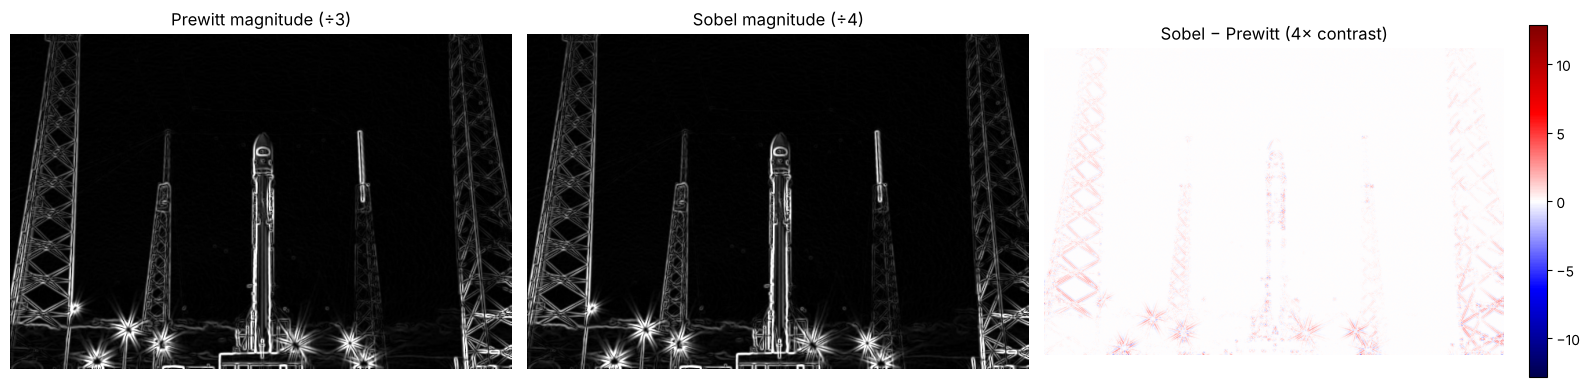

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
v = np.percentile(mp, 99.5)
ax[0].imshow(mp, cmap="gray", vmax=v); ax[0].set_title("Prewitt magnitude (÷3)")
ax[1].imshow(ms, cmap="gray", vmax=v); ax[1].set_title("Sobel magnitude (÷4)")
im = ax[2].imshow(ms - mp, cmap="seismic", vmin=-v / 4, vmax=v / 4); ax[2].set_title("Sobel − Prewitt (4× contrast)")
fig.colorbar(im, ax=ax[2], fraction=0.035)
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "task4_01_magnitudes_and_difference.png", dpi=110); plt.show()

## 2. Direction test: a perfect circle

A circle has edges in **every** direction. An ideal edge detector gives the same strength all around it, and a gradient direction `atan2(Gy, Gx)` that points exactly along the radius. We draw a smooth (anti-aliased) disc, apply the same Gaussian, and measure both along the edge.

Prewitt  peak edge strength over 360 directions: min 162.02  max 181.43  spread (max−min)/mean 11.6 %   direction error: mean 1.26°, max 2.21°
Sobel    peak edge strength over 360 directions: min 165.82  max 181.45  spread (max−min)/mean  9.2 %   direction error: mean 0.60°, max 1.27°


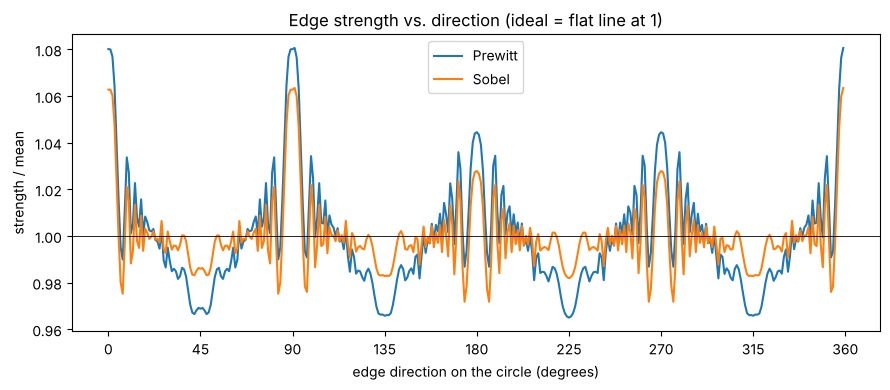

In [4]:
N, R, SS = 256, 80, 8
big = np.zeros((N * SS, N * SS), np.uint8)
cv2.circle(big, (N * SS // 2, N * SS // 2), R * SS, 255, -1)
disc = cv2.resize(big, (N, N), interpolation=cv2.INTER_AREA).astype(np.float32)   # anti-aliased
disc = cv2.GaussianBlur(disc, KSIZE, SIGMA)

c = (N - 1) / 2
theta = np.arange(0, 360, 1.0)                       # 360 edge directions
radii = np.arange(R - 5, R + 5, 0.05)                # sample across the edge
T, RR = np.meshgrid(np.radians(theta), radii, indexing="ij")
mapx = (c + RR * np.cos(T)).astype(np.float32)
mapy = (c + RR * np.sin(T)).astype(np.float32)

iso = {}
for name in OPS:
    gx, gy, m = grad(disc, name)
    samp = lambda a: cv2.remap(a, mapx, mapy, cv2.INTER_CUBIC)
    sm, sx, sy = samp(m), samp(gx), samp(gy)
    i = sm.argmax(axis=1)                                 # peak of the edge on each ray
    rows = np.arange(len(theta))
    peak = sm[rows, i]
    # bright disc on dark background → gradient points inward (θ + 180°)
    err = np.degrees(np.angle(np.exp(1j * (np.arctan2(sy[rows, i], sx[rows, i]) - (np.radians(theta) + np.pi)))))
    iso[name] = (theta, peak)
    print(f"{name:8s} peak edge strength over 360 directions: min {peak.min():6.2f}  max {peak.max():6.2f}  "
          f"spread (max−min)/mean {(peak.max() - peak.min()) / peak.mean() * 100:4.1f} %   "
          f"direction error: mean {np.abs(err).mean():.2f}°, max {np.abs(err).max():.2f}°")

plt.figure(figsize=(9, 4))
for name, (t, m) in iso.items():
    plt.plot(t, m / m.mean(), lw=1.5, label=name)
plt.axhline(1, color="k", lw=0.6)
plt.xlabel("edge direction on the circle (degrees)"); plt.ylabel("strength / mean")
plt.xticks(range(0, 361, 45)); plt.legend(); plt.title("Edge strength vs. direction (ideal = flat line at 1)")
plt.tight_layout(); plt.savefig(OUT / "task4_02_direction_test.png", dpi=110); plt.show()

## 3. Noise test

Same as in Tasks 1–3: add Gaussian noise (σ = 15) and compare edge/noise ratios (99.5th percentile of the magnitude ÷ mean magnitude in a flat sky patch). The ratio does not depend on the gain.

In [5]:
rng = np.random.default_rng(42)
noisy = np.clip(gray + rng.normal(0, 15, gray.shape), 0, 255).astype(np.float32)
sky = (slice(10, 110), slice(10, 160))
print(f"{'input':22s} {'Prewitt':>8s} {'Sobel':>8s}")
for label, img in [("clean, no blur", gray), ("clean, Gauss", smooth),
                   ("noisy, no blur", noisy), ("noisy, Gauss", cv2.GaussianBlur(noisy, KSIZE, SIGMA))]:
    row = []
    for name in OPS:
        m = grad(img, name)[2]
        row.append(np.percentile(m, 99.5) / m[sky].mean())
    print(f"{label:22s} {row[0]:8.1f} {row[1]:8.1f}")

input                   Prewitt    Sobel
clean, no blur             21.9     21.6
clean, Gauss               23.5     23.3
noisy, no blur              5.8      5.7
noisy, Gauss                8.4      8.2


## 4. Speed (CPU, 640×427, both directions + magnitude)

In [6]:
def bench(fn, n=200):
    fn(); t = time.perf_counter()
    for _ in range(n): fn()
    return (time.perf_counter() - t) / n * 1e3

print(f"Prewitt filter2D      : {bench(lambda: grad(smooth, 'Prewitt')):.3f} ms")
print(f"Sobel   filter2D      : {bench(lambda: grad(smooth, 'Sobel')):.3f} ms")
print(f"Sobel   cv2.Sobel     : {bench(lambda: cv2.magnitude(cv2.Sobel(smooth, cv2.CV_32F, 1, 0, ksize=3), cv2.Sobel(smooth, cv2.CV_32F, 0, 1, ksize=3))):.3f} ms")

Prewitt filter2D      : 0.674 ms


Sobel   filter2D      : 0.648 ms


Sobel   cv2.Sobel     : 0.441 ms
